# Analiza hate speech wokół wydarzenia – Bluesky: Naloty_ICE_Los_Angeles (model, tylko `hate`)

Kopia notebooka zespołu `notebooks/4_analizy_llm_hate_migrant/wykop/<wydarzenie>/` przerobiona na **jedną etykietę `hate`**
z naszego klasyfikatora – najlepszego modelu wg gold standardu (`reports/gold_model_eval/best_model.json`, notebook
`notebooks/3_gold_standard/08_gold_standard_eval.ipynb`).

**Komentarze:** te same co u zespołu – filtr tematyczny (`scripts/topic_filter.py`: słownik 1/1 albo regex migracji).
**Etykieta `hate`** = `hate_final` z `data/interim/bluesky/<wydarzenie>/<model>/comments.csv`: obelga ze słownika
(`hate_auto`) **albo** model (`prob_hate_max ≥ 0.5`) dla pozostałych komentarzy. Daty, wątki, autorzy, lajki – z `clean/`.

**Okresy:** `przed` = `relative_day < 0`, `po` = `relative_day >= 0` (zmień `POST_FROM_DAY`).
Inne wydarzenie / platforma: zmień `PLATFORM` i `EVENT` w komórce konfiguracyjnej.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint
from wordcloud import WordCloud

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())

# ---- konfiguracja ----
PLATFORM = "bluesky"
EVENT = "Naloty_ICE_Los_Angeles"
EVENT_FOLDER = "2025-06-06_Naloty_ICE_Los_Angeles"
MODEL = None            # None = najlepszy z reports/gold_model_eval/best_model.json; albo np. "herbert", "polbert", "roberta_banpl"
LABEL_COLUMN = None     # None = jak w best_model.json (hate_final = słownik + model); "hate_pred_max" = sam model
POST_FROM_DAY = 0       # od którego relative_day liczymy okres "po"
MIN_DAILY_N = 10        # min. liczba komentarzy w dniu, by liczyć dzienny odsetek w testach
TOP_N_WORDS = 20
SEED = 42

LABELS = ["hate"]
LABEL_NAMES = {"hate": "hate (ogólny)"}

# kolory: kategoryczne sloty w stałej kolejności + neutralne tusze (jak u zespołu)
COLORS = {"komentarze": "#2a78d6", "hate": "#eb6834", "przed": "#8a8984", "po": "#2a78d6"}
BAR_BG = "#b7d3f6"
INK, INK2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)


def fmt_p(t, digits=3):
    # kolumny z p-value jako tekst w notacji naukowej (round() zamieniłby małe p na 0)
    t = t.copy()
    for c in t.columns:
        if c == "p" or c.startswith("p "):
            t[c] = t[c].map(lambda v: f"{v:.3g}")
    return t.round(digits)

## 0. Wczytanie danych

In [2]:
META_COLS = ["comment_id", "platform", "relative_day", "created_date", "created_at", "thread_id", "post_id",
             "depth", "author_id", "likes", "text"]

best_p = ROOT / "reports" / "gold_model_eval" / "best_model.json"
BEST = json.loads(best_p.read_text(encoding="utf-8")) if best_p.exists() else {}
MODEL_DIR = MODEL or BEST.get("folder")
assert MODEL_DIR, "Brak reports/gold_model_eval/best_model.json – odpal notebooks/3_gold_standard/08 albo ustaw MODEL"
LABEL = LABEL_COLUMN or BEST.get("label_column", "hate_final")
MODEL_NAME = BEST.get("model", MODEL_DIR) if MODEL_DIR == BEST.get("folder") else MODEL_DIR


def load_event(platform=PLATFORM, event_folder=EVENT_FOLDER, post_from_day=POST_FROM_DAY):
    event_date = pd.Timestamp(event_folder[:10])
    event_dir = ROOT / "data" / "interim" / platform / event_folder
    pred_file = event_dir / MODEL_DIR / "comments.csv"
    clean_file = event_dir / "clean" / "comments.csv"
    assert pred_file.exists(), f"Brak {pred_file.relative_to(ROOT)} – odpal notebook modelu (notebooks/2_modele_hate/04/05/07)"

    res = pd.read_csv(pred_file, encoding="utf-8-sig", dtype={"comment_id": str})
    clean = pd.read_csv(clean_file, encoding="utf-8-sig", dtype={"comment_id": str},
                        usecols=lambda c: c in META_COLS).drop_duplicates("comment_id")
    df = res.merge(clean, on="comment_id", how="inner")
    df["created_date"] = pd.to_datetime(df["created_date"])
    df["hate"] = df[LABEL].fillna(0).astype(int).astype(bool)
    df["okres"] = np.where(df["relative_day"] >= post_from_day, "po", "przed")
    df["po"] = (df["okres"] == "po").astype(int)
    df["text"] = df["text"].fillna("").astype(str)
    df["likes"] = pd.to_numeric(df["likes"], errors="coerce")
    df["depth"] = pd.to_numeric(df["depth"], errors="coerce")
    return df, event_date, event_dir, len(res)


df, EVENT_DATE, EVENT_DIR, n_res = load_event()

print(f"platforma: {PLATFORM}  |  wydarzenie: {EVENT}  |  dzień 0 = {EVENT_DATE:%Y-%m-%d}")
print(f"model: {MODEL_NAME} ({MODEL_DIR}), etykieta: {LABEL}")
print("katalog:", EVENT_DIR.relative_to(ROOT))
print(f"wiersze w {MODEL_DIR}/comments.csv: {n_res}, po złączeniu z clean: {len(df)}")
print("źródło etykiety hate=1:", df.loc[df["hate"], "label_source"].value_counts().to_dict())
print(f"zakres relative_day: {df['relative_day'].min()} .. {df['relative_day'].max()}")
SMALL = len(df) < 200 or df["okres"].nunique() < 2
if SMALL:
    print(f"⚠️ Mało komentarzy ({len(df)}) – wyniki testów i wykresy są tylko orientacyjne; część testów może zostać pominięta.")

platforma: bluesky  |  wydarzenie: Naloty_ICE_Los_Angeles  |  dzień 0 = 2025-06-06
model: HerBERT-HS (herbert), etykieta: hate_final
katalog: data/interim/bluesky/2025-06-06_Naloty_ICE_Los_Angeles
wiersze w herbert/comments.csv: 11019, po złączeniu z clean: 11019
źródło etykiety hate=1: {'herbert': 2049, 'slownik': 19}
zakres relative_day: -28 .. 28


## 1. Liczba komentarzy i odsetek hate – przed, po i ogółem

In [3]:
def summarize(g):
    out = {"komentarze": len(g), "dni": g["relative_day"].nunique(),
           "komentarzy / dzień": len(g) / max(g["relative_day"].nunique(), 1)}
    for lab in LABELS:
        out[f"{lab} [n]"] = int(g[lab].sum())
    for lab in LABELS:
        out[f"{lab} [%]"] = 100 * g[lab].mean() if len(g) else np.nan
    out["hate ze słownika [n]"] = int((g[lab] & (g["label_source"] == "slownik")).sum())
    return pd.Series(out)


summary = pd.DataFrame({
    "przed": summarize(df[df["okres"] == "przed"]),
    "po": summarize(df[df["okres"] == "po"]),
    "ogółem": summarize(df),
}).T
display(summary.round(2))

,komentarze,dni,komentarzy / dzień,hate [n],hate [%],hate ze słownika [n]
przed,5630.0,28.0,201.07,943.0,16.75,12.0
po,5389.0,29.0,185.83,1125.0,20.88,7.0
ogółem,11019.0,57.0,193.32,2068.0,18.77,19.0


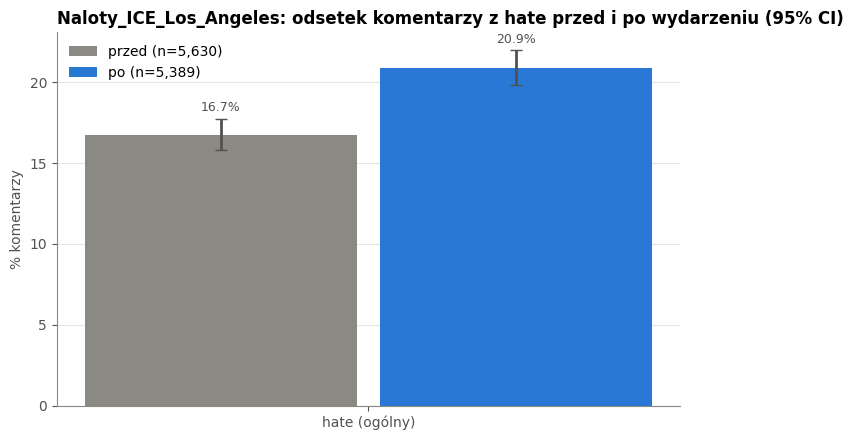

In [4]:
# odsetki z 95% CI (Wilson) - przed vs po
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(LABELS))
w = 0.38
for i, okres in enumerate(["przed", "po"]):
    g = df[df["okres"] == okres]
    if not len(g):
        continue
    k = np.array([g[lab].sum() for lab in LABELS])
    n = len(g)
    lo, hi = proportion_confint(k, n, method="wilson")
    p = k / n
    bars = ax.bar(x + (i - 0.5) * w, 100 * p, w - 0.03, color=COLORS[okres], label=f"{okres} (n={n:,})",
                  yerr=[np.clip(100 * (p - lo), 0, None), np.clip(100 * (hi - p), 0, None)], capsize=4, ecolor=INK2)
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in 100 * p], padding=3, color=INK2, fontsize=9)
ax.set_xticks(x, [LABEL_NAMES[l] for l in LABELS])
ax.set_ylabel("% komentarzy")
ax.set_title(f"{EVENT}: odsetek komentarzy z hate przed i po wydarzeniu (95% CI)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Liczba komentarzy per dzień

Na wszystkich wykresach dziennych: linia przerywana = dzień 0, kropkowana = dzień z max liczbą komentarzy, kreska-kropka = dzień z min liczbą komentarzy.

max: dzień 26 (2025-07-02), 532 komentarzy
min: dzień 14 (2025-06-20), 77 komentarzy


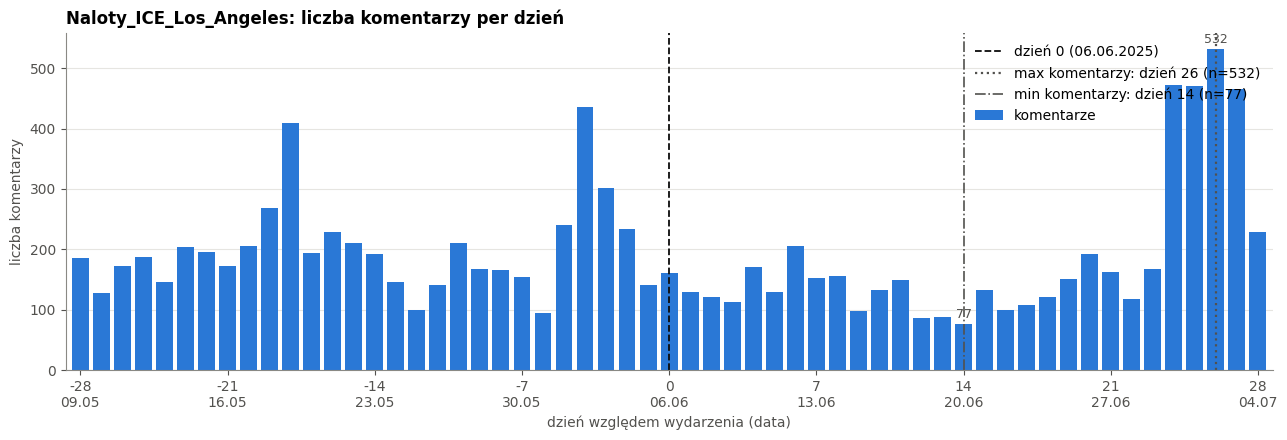

In [5]:
days = pd.RangeIndex(min(df["relative_day"].min(), 0), max(df["relative_day"].max(), 0) + 1, name="relative_day")
daily = (df.groupby("relative_day")
           .agg(komentarze=("comment_id", "size"), hate=("hate", "sum"))
           .reindex(days, fill_value=0))
daily["data"] = EVENT_DATE + pd.to_timedelta(daily.index, unit="D")
for lab in LABELS:
    daily[f"{lab}_%"] = 100 * daily[lab] / daily["komentarze"].replace(0, np.nan)

DAY_MAX = int(daily["komentarze"].idxmax())
DAY_MIN = int(daily["komentarze"].idxmin())
print(f"max: dzień {DAY_MAX} ({daily.loc[DAY_MAX, 'data']:%Y-%m-%d}), {daily.loc[DAY_MAX, 'komentarze']} komentarzy")
print(f"min: dzień {DAY_MIN} ({daily.loc[DAY_MIN, 'data']:%Y-%m-%d}), {daily.loc[DAY_MIN, 'komentarze']} komentarzy")


def format_days_axis(ax, step=7):
    ticks = [d for d in daily.index if d % step == 0]
    ax.set_xticks(ticks, [f"{d}\n{daily.loc[d, 'data']:%d.%m}" for d in ticks])
    ax.set_xlim(daily.index.min() - 0.7, daily.index.max() + 0.7)
    ax.set_xlabel("dzień względem wydarzenia (data)")


def mark_days(ax):
    n_max, n_min = daily.loc[DAY_MAX, "komentarze"], daily.loc[DAY_MIN, "komentarze"]
    ax.axvline(0, color=INK, ls="--", lw=1.3, label=f"dzień 0 ({EVENT_DATE:%d.%m.%Y})")
    ax.axvline(DAY_MAX, color=INK2, ls=":", lw=1.6, label=f"max komentarzy: dzień {DAY_MAX} (n={n_max})")
    ax.axvline(DAY_MIN, color=INK2, ls="-.", lw=1.2, label=f"min komentarzy: dzień {DAY_MIN} (n={n_min})")
    format_days_axis(ax)


fig, ax = plt.subplots()
ax.bar(daily.index, daily["komentarze"], width=0.8, color=COLORS["komentarze"], label="komentarze")
for d in (DAY_MAX, DAY_MIN):
    ax.annotate(f"{daily.loc[d, 'komentarze']}", (d, daily.loc[d, "komentarze"]), xytext=(0, 4),
                textcoords="offset points", ha="center", color=INK2, fontsize=9)
mark_days(ax)
ax.set_ylabel("liczba komentarzy")
ax.set_title(f"{EVENT}: liczba komentarzy per dzień")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3. Hate per dzień

3a – liczba komentarzy z hate, 3b – nałożona na liczbę wszystkich komentarzy (ta sama oś, te same jednostki), 3c – odsetek dzienny (normalizuje wolumen).

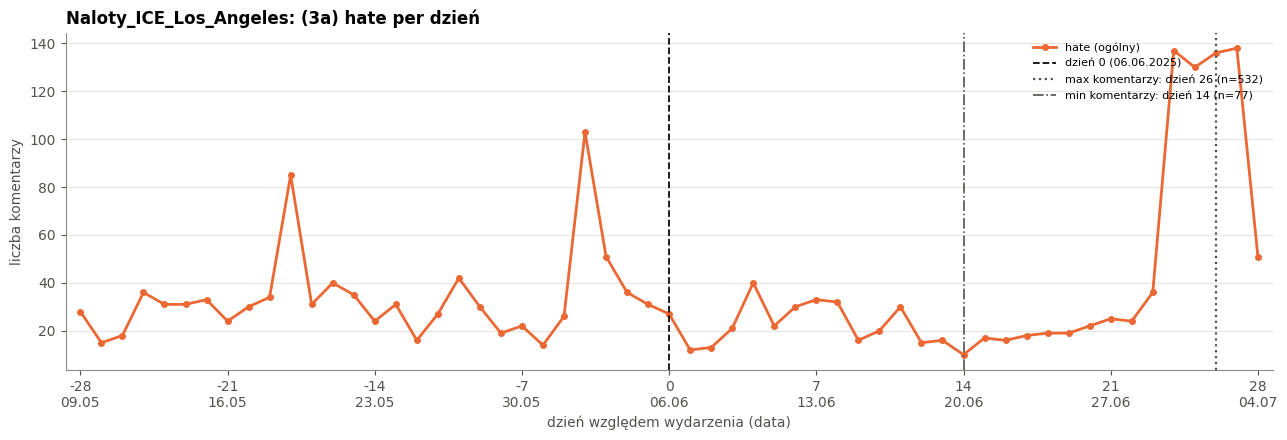

In [6]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily["hate"], marker="o", ms=4, color=COLORS["hate"], label=LABEL_NAMES["hate"])
mark_days(ax)
ax.set_ylabel("liczba komentarzy")
ax.set_title(f"{EVENT}: (3a) hate per dzień")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

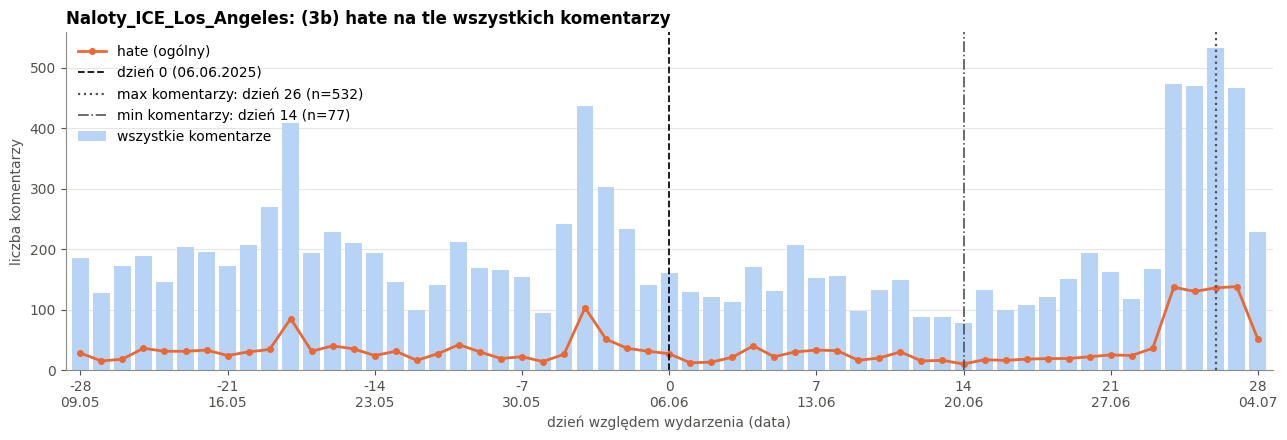

In [7]:
fig, ax = plt.subplots()
ax.bar(daily.index, daily["komentarze"], width=0.8, color=BAR_BG, label="wszystkie komentarze")
ax.plot(daily.index, daily["hate"], marker="o", ms=4, color=COLORS["hate"], label=LABEL_NAMES["hate"])
mark_days(ax)
ax.set_ylabel("liczba komentarzy")
ax.set_title(f"{EVENT}: (3b) hate na tle wszystkich komentarzy")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

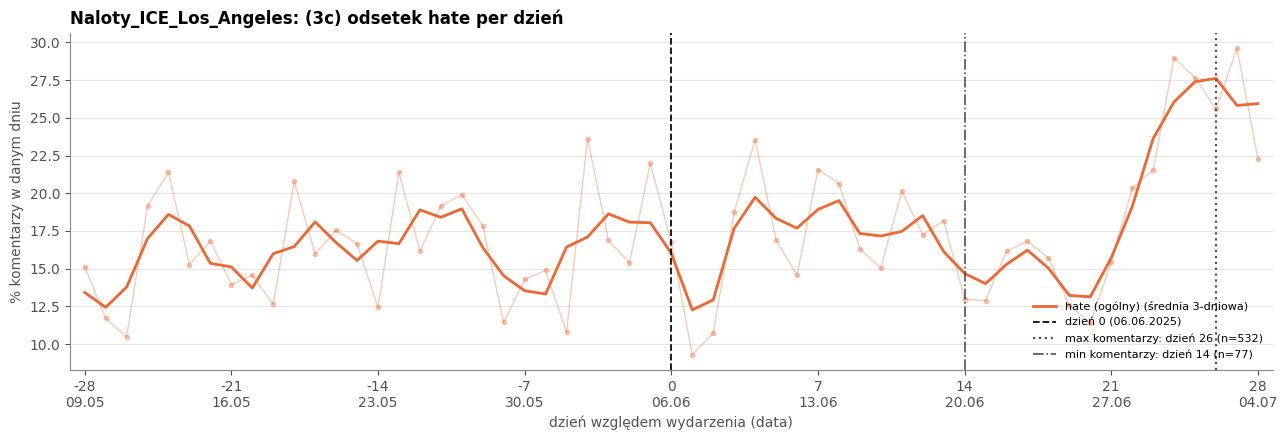

In [8]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily["hate_%"], marker="o", ms=3, lw=1, alpha=0.35, color=COLORS["hate"])
roll = daily["hate_%"].rolling(3, center=True, min_periods=1).mean()
ax.plot(daily.index, roll, color=COLORS["hate"], label=f"{LABEL_NAMES['hate']} (średnia 3-dniowa)")
mark_days(ax)
ax.set_ylabel("% komentarzy w danym dniu")
ax.set_title(f"{EVENT}: (3c) odsetek hate per dzień")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Top słowa w komentarzach `hate`

Tokenizacja: małe litery, bez linków/@wzmianek, słowa ≥ 3 litery, bez stop-słów. Brak lematyzacji – odmiany
(np. *ukraińcy* / *ukraińców*) liczą się osobno.

komentarze hate: 2068, unikalnych słów: 12751


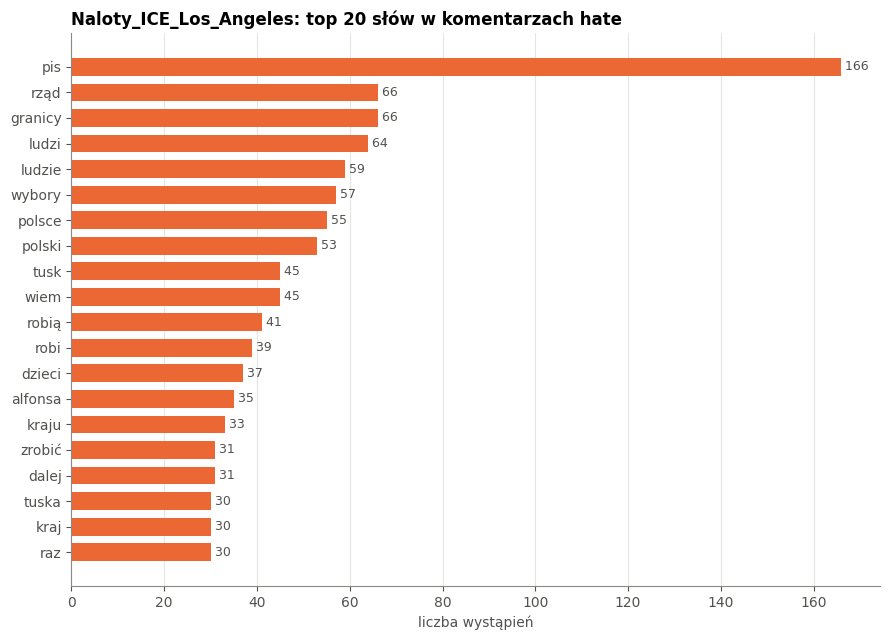

In [9]:
STOPWORDS_PL = set('''
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
'''.split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")


def tokenize(text):
    return [t for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower())) if t not in STOPWORDS_PL]


def top_words(texts, n=TOP_N_WORDS):
    return Counter(t for txt in texts for t in tokenize(txt))


hm = df[df["hate"]]
word_counts = top_words(hm["text"])
top = pd.DataFrame(word_counts.most_common(TOP_N_WORDS), columns=["słowo", "liczba"])
print(f"komentarze hate: {len(hm)}, unikalnych słów: {len(word_counts)}")

if len(top):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.barh(top["słowo"][::-1], top["liczba"][::-1], color=COLORS["hate"], height=0.7)
    for y, v in enumerate(top["liczba"][::-1]):
        ax.text(v, y, f" {v}", va="center", color=INK2, fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("liczba wystąpień")
    ax.set_title(f"{EVENT}: top {TOP_N_WORDS} słów w komentarzach hate")
    plt.tight_layout()
    plt.show()

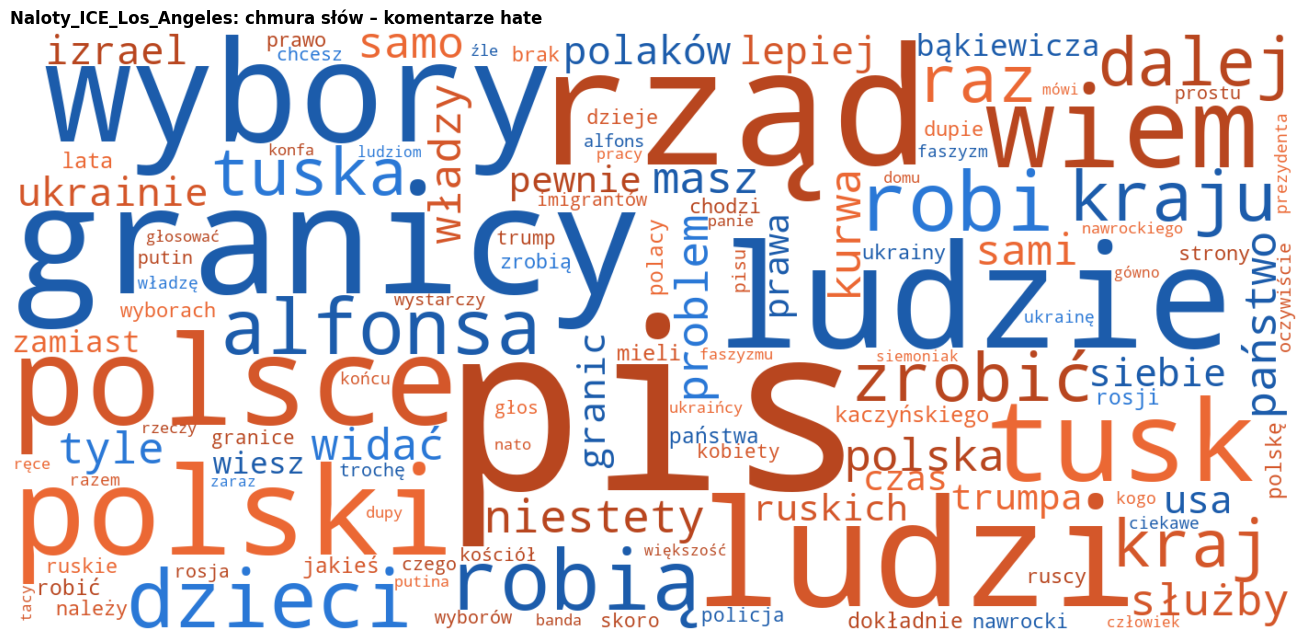

In [10]:
REDS = ["#b8461f", "#d4572a", "#eb6834", "#2a78d6", "#1c5cab"]


def wc_color(word, font_size, position, orientation, random_state=None, **kw):
    return random_state.choice(REDS)


if word_counts:
    wc = WordCloud(width=1400, height=650, background_color="white", max_words=120, color_func=wc_color,
                   random_state=SEED, prefer_horizontal=0.9).generate_from_frequencies(word_counts)
    fig, ax = plt.subplots(figsize=(14, 6.5))
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{EVENT}: chmura słów – komentarze hate")
    plt.tight_layout()
    plt.show()

In [11]:
# te same top słowa osobno przed i po - co się zmieniło w słownictwie
side = pd.concat({okres: pd.DataFrame(top_words(hm.loc[hm["okres"] == okres, "text"]).most_common(TOP_N_WORDS),
                                      columns=["słowo", "liczba"]) for okres in ["przed", "po"]}, axis=1)
side

przed                 po       
       słowo liczba       słowo liczba
0        pis     82         pis     84
1     polsce     27     granicy     48
2     ludzie     23        rząd     47
3      ludzi     22       ludzi     42
4     polski     21      wybory     39
5       tusk     20      ludzie     36
6       wiem     20      polski     32
7       rząd     19       robią     28
8    alfonsa     19      polsce     28
9     wybory     18        tusk     25
10     prawa     18        wiem     25
11   granicy     18      służby     24
12      robi     17     państwo     23
13    dzieci     17        robi     22
14     tuska     17  bąkiewicza     22
15    lepiej     17       dalej     21
16   ruskich     17      zrobić     20
17  nawrocki     16      dzieci     20
18     kraju     16     problem     19
19     kurwa     16        kraj     19

## 5. Testy statystyczne: przed vs po

Dla etykiety `hate` – te same trzy testy co u zespołu:

1. **Test χ² (tabela 2×2)** okres × etykieta – czy odsetek różni się między okresami; różnica odsetków z 95% CI (Newcombe),
   iloraz ryzyka (RR) i wielkość efektu **Cohen's h** (0.2 mały, 0.5 średni, 0.8 duży).
2. **Regresja logistyczna z błędami klastrowanymi po wątku** – komentarze w jednym wątku nie są niezależne
   (jedna dyskusja potrafi „nakręcić” hejt), więc χ² zawyża istotność. To bardziej konserwatywny test tej samej hipotezy.
3. **Mann–Whitney U na dziennych odsetkach** – jednostką jest dzień (tylko dni z ≥ `MIN_DAILY_N` komentarzami).

Istotność (`ALPHA` = 0.05) sprawdzana jest **osobno dla każdego testu**, `zgodność` = ile z 3 testów wskazuje zmianę.
(Korekta Holma u zespołu dotyczyła 4 etykiet; tutaj jest jedna etykieta, więc p = p (Holm).)

**Wniosek główny:** zmiana jest istotna, jeśli wychodzi w **obu ostrożnych testach** – logit klastrowanym (wątki)
**i** Mann–Whitney (dni). χ² pokazany do porównania – przy tylu komentarzach prawie zawsze wychodzi istotny.

In [12]:
ALPHA = 0.05
TESTS = {"hate": df}

rows = []
for name, d in TESTS.items():
    lab = name
    pre, post = d[d["okres"] == "przed"][lab], d[d["okres"] == "po"][lab]
    k1, n1, k2, n2 = pre.sum(), len(pre), post.sum(), len(post)
    row = {"etykieta": name, "n przed": n1, "n po": n2}
    if min(n1, n2) == 0:
        print("⚠️ brak komentarzy w jednym z okresów – testy pominięte")
        rows.append(row)
        continue
    p1, p2 = k1 / n1, k2 / n2
    row.update({"przed %": 100 * p1, "po %": 100 * p2, "różnica pp": 100 * (p2 - p1), "RR": p2 / p1 if p1 else np.nan,
                "Cohen h": 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1))})
    try:
        chi2, p_chi, _, _ = stats.chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]])
        lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
        row.update({"95% CI pp": f"[{100 * lo:.2f}, {100 * hi:.2f}]", "χ²": chi2, "p χ²": p_chi})
    except ValueError as e:
        print("χ² pominięty:", e)
    try:
        m = smf.logit("y ~ po", data=d.assign(y=d[lab].astype(int))).fit(
            disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread_id"])[0]})
        row.update({"OR (logit, klaster)": np.exp(m.params["po"]), "p logit klaster": m.pvalues["po"]})
    except Exception as e:  # np. brak hejtu w jednym okresie (separacja)
        print("logit pominięty:", type(e).__name__, str(e)[:120])
    dd = d.groupby("relative_day").agg(n=(lab, "size"), k=(lab, "sum"))
    dd = dd[dd["n"] >= MIN_DAILY_N].assign(p=lambda x: x["k"] / x["n"])
    a, b = dd.loc[dd.index < POST_FROM_DAY, "p"], dd.loc[dd.index >= POST_FROM_DAY, "p"]
    if len(a) and len(b):
        row["p Mann-Whitney (dni)"] = stats.mannwhitneyu(a, b).pvalue
    else:
        print(f"Mann–Whitney pominięty: za mało dni z ≥ {MIN_DAILY_N} komentarzami (przed {len(a)}, po {len(b)})")
    rows.append(row)

tests = pd.DataFrame(rows).set_index("etykieta")
P_COLS = {"χ²": "p χ²", "logit klaster": "p logit klaster", "Mann-Whitney": "p Mann-Whitney (dni)"}
for test, col in P_COLS.items():
    if col not in tests:
        tests[col] = np.nan
    ok = tests[col].notna()
    tests[col + " (Holm)"] = np.nan
    if ok.any():
        tests.loc[ok, col + " (Holm)"] = multipletests(tests.loc[ok, col], method="holm")[1]
    tests[f"istotne {test}"] = tests[col + " (Holm)"] < ALPHA
tests["zgodność"] = tests[[f"istotne {t}" for t in P_COLS]].sum(axis=1).astype(str) + "/3"
tests["istotne (logit klaster i Mann-Whitney)"] = tests["istotne logit klaster"] & tests["istotne Mann-Whitney"]

display(fmt_p(tests, 3))
display(tests[[f"istotne {t}" for t in P_COLS] + ["zgodność", "istotne (logit klaster i Mann-Whitney)"]]
        .replace({True: "✅", False: "❌"}))

,n przed,n po,przed %,po %,różnica pp,RR,Cohen h,95% CI pp,χ²,p χ²,...,p logit klaster,p Mann-Whitney (dni),p χ² (Holm),istotne χ²,p logit klaster (Holm),istotne logit klaster,p Mann-Whitney (dni) (Holm),istotne Mann-Whitney,zgodność,istotne (logit klaster i Mann-Whitney)
etykieta,,,,,,,,,,,,,,,,,,,,,
hate,5630,5389,16.75,20.876,4.126,1.246,0.106,"[2.67, 5.59]",30.481,3.37e-08,...,0.000182,0.188,3.37e-08,True,0.000182,True,0.188,False,2/3,False


,istotne χ²,istotne logit klaster,istotne Mann-Whitney,zgodność,istotne (logit klaster i Mann-Whitney)
etykieta,,,,,
hate,✅,✅,❌,2/3,❌


In [13]:
for name, r in tests.iterrows():
    if pd.isna(r.get("różnica pp")):
        print(f"{name}: brak danych do porównania")
        continue
    kier = "wzrost" if r["różnica pp"] > 0 else "spadek"
    sig = "ISTOTNA" if r["istotne (logit klaster i Mann-Whitney)"] else "nieistotna"
    marks = ", ".join("{} {}".format(t, "✅" if r["istotne " + t] else "❌") for t in P_COLS)
    print(f"{name:24s}: {r['przed %']:.2f}% -> {r['po %']:.2f}% ({kier} o {abs(r['różnica pp']):.2f} pp, "
          f"RR={r['RR']:.2f}, h={r['Cohen h']:.3f}) - różnica {sig} "
          f"[{marks}; zgodność {r['zgodność']}]")

hate                    : 16.75% -> 20.88% (wzrost o 4.13 pp, RR=1.25, h=0.106) - różnica nieistotna [χ² ✅, logit klaster ✅, Mann-Whitney ❌; zgodność 2/3]


## 6. Kogo obrażano? Komentarze `hate` po wydarzeniu wg grup (słowa kluczowe)

Grupy migrantów z notebooków zespołu (te same wyrażenia regularne). Tu liczone wśród **wszystkich** komentarzy `hate`
(nie tylko hejtu wobec migrantów), więc „brak słowa kluczowego” obejmuje też hejt wobec polityków, rozmówców itd.
Komentarz może trafić do kilku grup: widok **wielo-etykietowy** (sumy > 100%) i **rozłączny**.

In [14]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
GROUP_RE = {g: re.compile(p) for g, p in TARGET_GROUPS.items()}
GROUP_COLORS = dict(zip(TARGET_GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

hm = df[df["hate"]].copy()
for g, rx in GROUP_RE.items():
    hm[g] = hm["text"].str.lower().apply(lambda t: bool(rx.search(t)))
n_groups = hm[list(TARGET_GROUPS)].sum(axis=1)
hm["grupa"] = np.select(
    [n_groups == 0, n_groups > 1],
    ["brak słowa kluczowego", "kilka grup"],
    default=hm[list(TARGET_GROUPS)].idxmax(axis=1) if len(hm) else "",
)
hm_po = hm[hm["okres"] == "po"]

multi = pd.DataFrame({okres: 100 * hm.loc[hm["okres"] == okres, list(TARGET_GROUPS)].mean()
                      for okres in ["przed", "po"]})
multi["po [n]"] = hm_po[list(TARGET_GROUPS)].sum()
excl = pd.concat({okres: hm.loc[hm["okres"] == okres, "grupa"].value_counts() for okres in ["przed", "po"]},
                 axis=1).fillna(0).astype(int)
excl_pct = 100 * excl / excl.sum().replace(0, np.nan)

print(f"hate po wydarzeniu: {len(hm_po)} komentarzy")
print("\nwidok wielo-etykietowy (% komentarzy hate zawierających grupę):")
display(multi.round(2))
print("rozłączny (n i %):")
display(pd.concat([excl, excl_pct.round(2).add_suffix(" %")], axis=1))

hate po wydarzeniu: 1125 komentarzy

widok wielo-etykietowy (% komentarzy hate zawierających grupę):


,przed,po,po [n]
Ukraińcy,10.60,6.84,77
Muzułmanie / Arabowie / Bliski Wschód,2.23,2.13,24
Afrykanie / czarnoskórzy,1.91,1.33,15
Migranci / uchodźcy (ogólnie),5.83,5.33,60


rozłączny (n i %):


,przed,po,przed %,po %
grupa,,,,
brak słowa kluczowego,761,954,80.70,84.80
Ukraińcy,93,76,9.86,6.76
Migranci / uchodźcy (ogólnie),51,58,5.41,5.16
Muzułmanie / Arabowie / Bliski Wschód,15,21,1.59,1.87
Afrykanie / czarnoskórzy,12,11,1.27,0.98
kilka grup,11,5,1.17,0.44


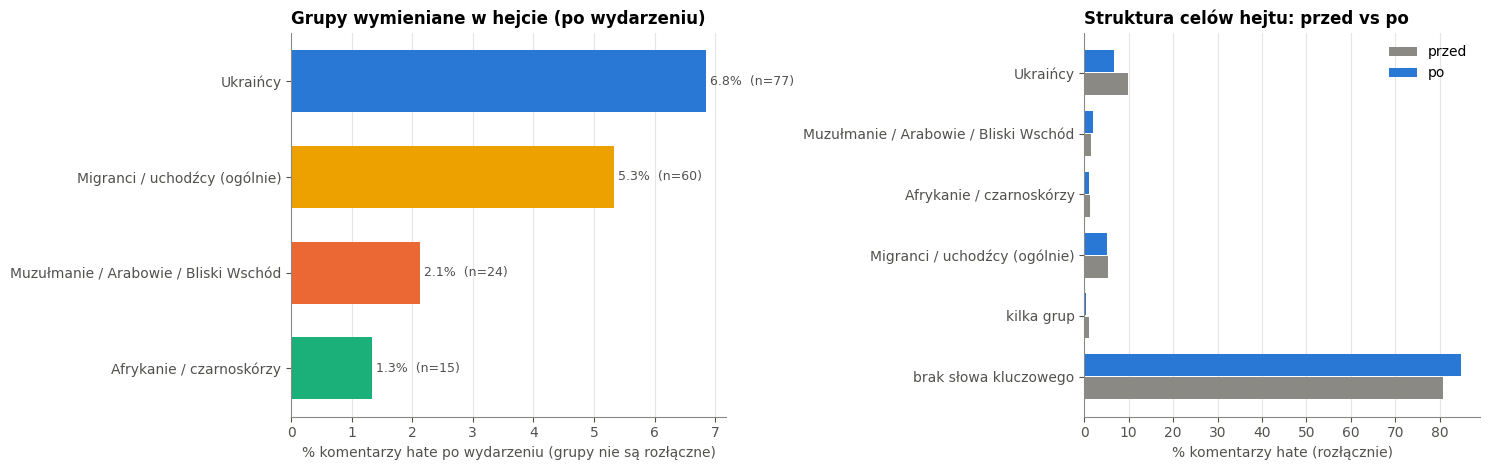

χ² struktura grup przed vs po: χ²=11.24, df=5, p=0.0468


In [15]:
if len(hm_po):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

    ax = axes[0]
    s = multi["po"].fillna(0).sort_values()
    ax.barh(s.index, s.values, color=[GROUP_COLORS[g] for g in s.index], height=0.65)
    for y, (g, v) in enumerate(s.items()):
        ax.text(v, y, f" {v:.1f}%  (n={multi.loc[g, 'po [n]']})", va="center", color=INK2, fontsize=9)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlabel("% komentarzy hate po wydarzeniu (grupy nie są rozłączne)")
    ax.set_title("Grupy wymieniane w hejcie (po wydarzeniu)")

    ax = axes[1]
    order = [*TARGET_GROUPS, "kilka grup", "brak słowa kluczowego"]
    e = excl_pct.reindex(order).fillna(0)
    y = np.arange(len(order))
    for i, okres in enumerate(["przed", "po"]):
        if okres in e:
            ax.barh(y + (0.5 - i) * 0.38, e[okres], 0.36, color=COLORS[okres], label=okres)
    ax.set_yticks(y, order)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlabel("% komentarzy hate (rozłącznie)")
    ax.set_title("Struktura celów hejtu: przed vs po")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # czy struktura celów zmieniła się po wydarzeniu?
    t = excl.loc[excl.sum(axis=1) > 0]
    if t.shape[1] == 2 and t.shape[0] > 1 and (t.sum() > 0).all():
        chi2, p, dof, _ = stats.chi2_contingency(t)
        print(f"χ² struktura grup przed vs po: χ²={chi2:.2f}, df={dof}, p={p:.3g}")
    else:
        print("χ² struktury grup pominięty (za mało hejtu w jednym z okresów)")

In [16]:
# przykłady (losowe) do weryfikacji, czy słowa kluczowe dobrze przypisują grupy
for g in [*TARGET_GROUPS, "kilka grup", "brak słowa kluczowego"]:
    sample = hm_po[hm_po["grupa"] == g]
    print(f"\n=== {g} (n={len(sample)}) ===")
    for t in sample["text"].sample(min(4, len(sample)), random_state=SEED):
        print(" -", t[:220].replace("\n", " "))


=== Ukraińcy (n=76) ===
 - żebym wiedziała, że "nie wszyscy Ukraińcy to ch...e"... Jak dotąd nie spotkałam takich
 - Raporty o falszerstwach byly zglaszane do ABW axte krety Pisowskie to ukrywali ...Panie Tusk nie nabieraj Pan wody w gebe, tylko zdymisjonuj Pan tego kreta Siemoniaka...Czy dalej bedzie tolerowal swoje kolesiostwo z tym 
 - Nic dodać nic ująć, diagnoza trafna. A tak na marginesie gdzie służby podległe Siemoniakowi Rumuni potrafili to ukrócić, w Polsce hulaj dusza służb nie ma, Siemoniak ma spokój
 - A i to co najważniejsze: PISowi nie udało się i nie uda się ukraść ani jednej złotówki z KPO

=== Muzułmanie / Arabowie / Bliski Wschód (n=21) ===
 - w stylu... jeżeli pis proponuję ustawę o zakazie wjazdu do Polski osób z Bliskiego Wschodu, to stargetowac Górali info "pis okrada Podhale zakazując wjazdu turystom z krajów arabskich, nie pozwól na to" itd.
 - Wtedy trzeba dać Saudom głowice i wszyscy są bezpieczni, bo jak tylko Izrael i Pakistan mają atomówki w regionie to ni

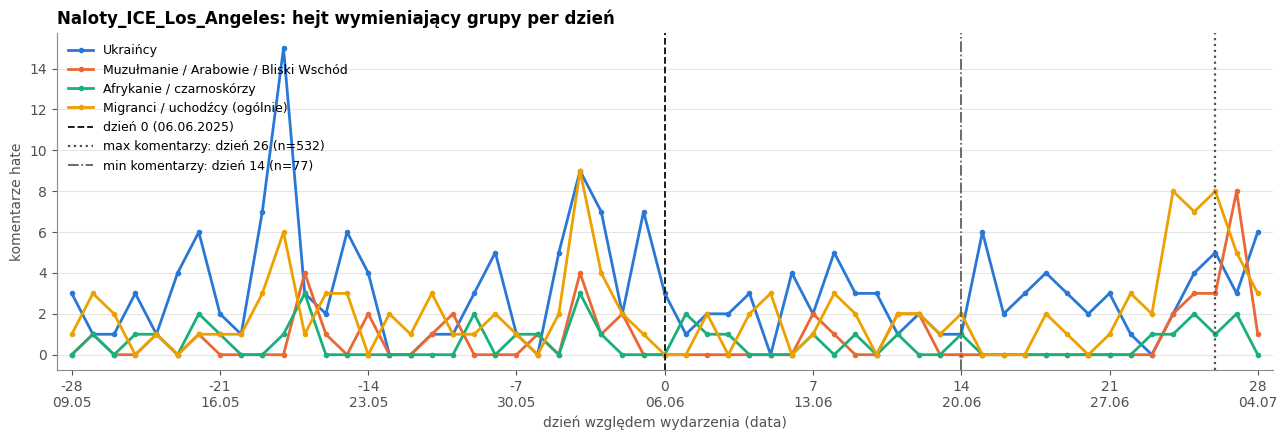

In [17]:
# dzienny przebieg hejtu wobec poszczególnych grup (wielo-etykietowo)
daily_groups = hm.groupby("relative_day")[list(TARGET_GROUPS)].sum().reindex(days, fill_value=0)
fig, ax = plt.subplots()
for g in TARGET_GROUPS:
    ax.plot(daily_groups.index, daily_groups[g], marker="o", ms=3, color=GROUP_COLORS[g], label=g)
mark_days(ax)
ax.set_ylabel("komentarze hate")
ax.set_title(f"{EVENT}: hejt wymieniający grupy per dzień")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 7. Dodatkowe analizy

### 7.1 Przerwany szereg czasowy (interrupted time series)

Test przed/po porównuje tylko średnie. Model segmentowy rozdziela **skok poziomu** w dniu 0 (`po`) od
**zmiany trendu** (`relative_day:po`) – odróżnia „jednorazowy wybuch” od trwałego wzrostu. Regresja logistyczna na
poziomie komentarza, błędy klastrowane po wątku; współczynniki jako ilorazy szans (OR).

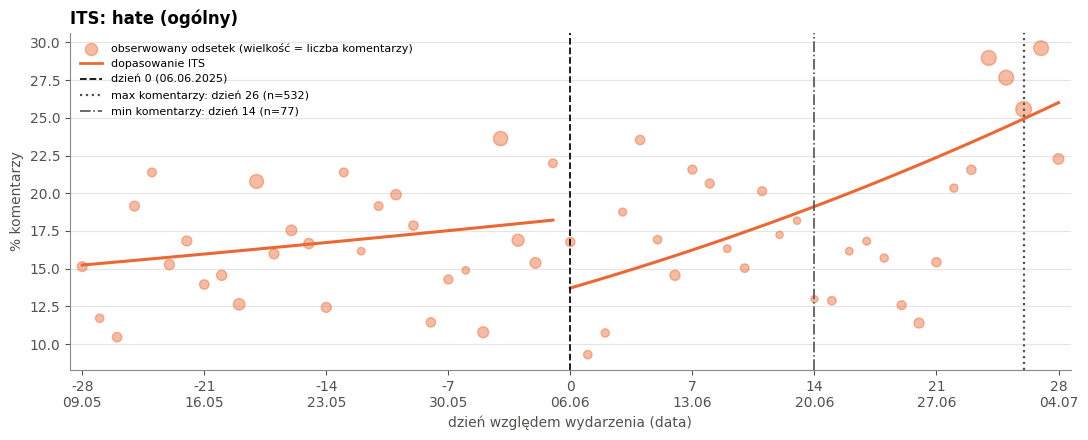

OR          95% CI       p
etykieta człon                                         
hate     po               0.708  [0.536, 0.935]  0.0151
         relative_day     1.008  [0.997, 1.019]   0.166
         relative_day:po  1.021  [1.004, 1.037]   0.013

In [18]:
its_rows = []
fig, ax = plt.subplots(figsize=(11, 4.5))
lab = "hate"
try:
    m = smf.logit("y ~ relative_day + po + relative_day:po", data=df.assign(y=df[lab].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(df["thread_id"])[0]})
    for term in ["po", "relative_day", "relative_day:po"]:
        its_rows.append({"etykieta": lab, "człon": term, "OR": np.exp(m.params[term]),
                         "95% CI": f"[{np.exp(m.conf_int().loc[term, 0]):.3f}, {np.exp(m.conf_int().loc[term, 1]):.3f}]",
                         "p": m.pvalues[term]})
    pred = m.predict(pd.DataFrame({"relative_day": daily.index, "po": (daily.index >= POST_FROM_DAY).astype(int)}))
    ok = daily["komentarze"] >= MIN_DAILY_N
    ax.scatter(daily.index[ok], daily.loc[ok, f"{lab}_%"], s=8 + daily.loc[ok, "komentarze"] / daily["komentarze"].max() * 120,
               color=COLORS[lab], alpha=0.45, label="obserwowany odsetek (wielkość = liczba komentarzy)")
    for seg in (daily.index < POST_FROM_DAY, daily.index >= POST_FROM_DAY):
        ax.plot(daily.index[seg], 100 * np.asarray(pred)[seg], color=COLORS[lab], lw=2.2)
    ax.plot([], [], color=COLORS[lab], label="dopasowanie ITS")
except Exception as e:
    print("ITS pominięty:", type(e).__name__, str(e)[:150])
mark_days(ax)
ax.set_ylabel("% komentarzy")
ax.set_title(f"ITS: {LABEL_NAMES[lab]}")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
if its_rows:
    display(fmt_p(pd.DataFrame(its_rows).set_index(["etykieta", "człon"]), 3))

### 7.2 Koncentracja autorów

Czy hejt to „wielu ludzi po trochu”, czy garstka bardzo aktywnych kont? I czy po wydarzeniu dochodzą **nowi** hejterzy
(autorzy, którzy nie pisali nic przed dniem 0)?

autorów hate: 678; top 10% autorów (68) pisze 42.3% hejtu, top 10 kont: 13.7%
hejterzy po wydarzeniu: 436, z czego nowych (nieaktywnych przed): 126 (28.9%), odpowiadają za 14.1% komentarzy hate po wydarzeniu


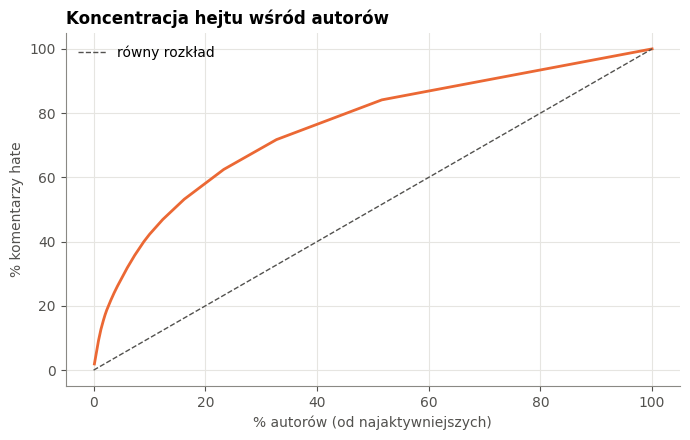

In [19]:
per_author = hm.groupby("author_id").size().sort_values(ascending=False)
if len(per_author):
    cum = per_author.cumsum() / per_author.sum()
    top10 = max(1, int(np.ceil(0.1 * len(per_author))))
    print(f"autorów hate: {len(per_author)}; top 10% autorów ({top10}) pisze {cum.iloc[top10 - 1]:.1%} hejtu, "
          f"top 10 kont: {per_author.head(10).sum() / per_author.sum():.1%}")

    authors_before = set(df.loc[df["okres"] == "przed", "author_id"])
    hm_po_authors = hm_po.groupby("author_id").size()
    if len(hm_po_authors):
        new = ~hm_po_authors.index.isin(authors_before)
        print(f"hejterzy po wydarzeniu: {len(hm_po_authors)}, z czego nowych (nieaktywnych przed): {new.sum()} ({new.mean():.1%}), "
              f"odpowiadają za {hm_po_authors[new].sum() / hm_po_authors.sum():.1%} komentarzy hate po wydarzeniu")

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=COLORS["hate"])
    ax.plot([0, 100], [0, 100], color=INK2, ls="--", lw=1, label="równy rozkład")
    ax.set_xlabel("% autorów (od najaktywniejszych)")
    ax.set_ylabel("% komentarzy hate")
    ax.set_title("Koncentracja hejtu wśród autorów")
    ax.grid(axis="x", visible=True)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 7.3 Zaangażowanie: czy hejt dostaje więcej polubień?

Mann–Whitney U na liczbie lajków, osobno w każdym okresie.

In [20]:
rows = []
for okres in ["przed", "po", "ogółem"]:
    d = df if okres == "ogółem" else df[df["okres"] == okres]
    for lab in LABELS:
        a, b = d.loc[d[lab], "likes"].dropna(), d.loc[~d[lab], "likes"].dropna()
        if len(a) and len(b):
            rows.append({"okres": okres, "etykieta": lab, "mediana lajków (z etykietą)": a.median(),
                         "mediana lajków (reszta)": b.median(), "średnia (z etykietą)": a.mean(),
                         "średnia (reszta)": b.mean(), "p Mann-Whitney": stats.mannwhitneyu(a, b).pvalue})
if rows:
    display(fmt_p(pd.DataFrame(rows).set_index(["okres", "etykieta"]), 2))

,,mediana lajków (z etykietą),mediana lajków (reszta),średnia (z etykietą),średnia (reszta),p Mann-Whitney
okres,etykieta,,,,,
przed,hate,1.0,1.0,1.99,2.04,0.073
po,hate,1.0,1.0,1.99,1.79,0.00781
ogółem,hate,1.0,1.0,1.99,1.92,0.0014


### 7.4 Gdzie powstaje hejt: wątki i głębokość dyskusji

Top materiały (wątki) z największą liczbą komentarzy hate po wydarzeniu oraz odsetek hejtu wg poziomu odpowiedzi (`depth`).

In [21]:
thr = (df[df["okres"] == "po"].groupby("thread_id")
       .agg(komentarze=("comment_id", "size"), hate=("hate", "sum")))
thr["hate %"] = 100 * thr["hate"] / thr["komentarze"]
top_thr = thr.sort_values("hate", ascending=False).head(10)
if thr["hate"].sum():
    print(f"top 10 wątków (z {len(thr)}) zawiera {top_thr['hate'].sum() / thr['hate'].sum():.1%} hejtu po wydarzeniu")
display(top_thr.round(1))

depth = df.groupby(["depth", "okres"])[["hate"]].mean().mul(100).unstack("okres").round(2)
depth["n"] = df.groupby("depth").size()
depth

top 10 wątków (z 1632) zawiera 14.4% hejtu po wydarzeniu


,komentarze,hate,hate %
thread_id,,,
P00154,158,63,39.9
P03317,45,15,33.3
P03011,23,13,56.5
P03010,22,12,54.5
P03280,25,12,48.0
P06535,28,11,39.3
P04388,33,10,30.3
P07961,52,9,17.3
P08580,21,9,42.9


hate            n
okres     po  przed      
depth                    
1      24.11  18.89  5571
2      17.65  15.67  2084
3      18.33  15.09  1145
4      17.35  15.90   711
5      13.66  13.14   463
6      16.98  15.76   343
7      18.35  11.63   238
8      18.60  11.40   200
9      14.49  12.00   144
10     18.37   5.63   120

### 7.5 Kategorie obelg (słownik regex) wśród hate – przed vs po

Ze słownika `src/lexicon/slurs.py` (kolumna `slur_categories` w pliku wyników modelu): które typy obelg rosną po wydarzeniu.

In [22]:
sc = (df.loc[df["hate"], ["comment_id", "okres", "slur_categories"]]
      .assign(slur_categories=lambda x: x["slur_categories"].fillna("").astype(str))
      .query("slur_categories != ''")
      .assign(kat=lambda x: x["slur_categories"].str.split(r";\s*")).explode("kat"))
if len(sc):
    n_okres = df["okres"].value_counts()
    cat = sc.groupby(["kat", "okres"]).size().unstack(fill_value=0).reindex(columns=["przed", "po"], fill_value=0)
    cat_rate = (cat / n_okres.reindex(cat.columns) * 1000).round(2).add_suffix(" / 1000 kom.")
    cat_rate["zmiana ×"] = (cat_rate["po / 1000 kom."] / cat_rate["przed / 1000 kom."].replace(0, np.nan)).round(2)
    display(pd.concat([cat, cat_rate], axis=1).sort_values("po", ascending=False))
else:
    print("brak komentarzy hate z obelgą ze słownika")

okres,przed,po,przed / 1000 kom.,po / 1000 kom.,zmiana ×
kat,,,,,
dehumanizacja,8,15,1.42,2.78,1.96
obelga,5,4,0.89,0.74,0.83
obelga_etniczna,0,2,0.00,0.37,NaN
kod_ironiczny,0,1,0.00,0.19,NaN
kod_spiskowy,0,1,0.00,0.19,NaN
obelga_etniczna_zlozenie,5,1,0.89,0.19,0.21
kod_historyczny,4,0,0.71,0.00,0.00
kod_inwazji,2,0,0.36,0.00,0.00
kod_prorosyjski,2,0,0.36,0.00,0.00
